# 04 Training-data statistics

Figures of the training data (2025) and the scored months: the target and its long tail, the stale and wrong-date
records, NM's clocks, the NM join window, the hour and the season, and the seasonal holdout. Three of them appear in
`docs/report.md`: fig04_05, fig04_06 and fig04_11 (the report's Figure 3). Each figure is preceded by the statement it
checks and the numbers it shows; its cell prints those numbers from the data before drawing them. Where a computed
number differs from the statement, the figure shows the data and the cell says so.

* Built and executed by `notebooks/build/build_04.py`; figures go to `docs/figures/fig04_*.png`.
* Inputs: `data/interim/movements.parquet` (target-masked movement frame) and `data/interim/target.parquet`
  (training targets), both from `python -m prc prepare`. No model is trained here.
* Every figure is drawn at a text width of 16 cm, so its font sizes are print sizes. Airports are labelled
  "Rome (LIRF)" throughout; the order is stated in each figure (region order, or sorted by a value).

**A cap in the source data.** Madrid and Barcelona have no target above 3,604 s (about 212,000 and 180,000
departures; 10 rows between 3,500 and 3,600 s, then none), Frankfurt and Munich none above 6,907 s and 6,899 s.
Targets above the cap cannot appear at these four airports: no wrong-date record, and no stale record whose delay
exceeds the cap, whatever their true rate. Figures 3, 4, 5 and 8 mark the cap.

**Definitions used throughout.**

| term | definition |
|---|---|
| target | `TAXITIME_SEC_mvt` = airport takeoff time minus airport off-block (block) time, seconds |
| block time | `MVT_TIME_UTC_mvt − target` (training departures only; blanked in the movement frame) |
| schedule delta | takeoff minus `SCHED_TIME_UTC_mvt`, seconds |
| NM proxy | takeoff minus NM's actual off-block `AOBT_3_flt`, seconds (target-free, known in 2026) |
| stale record | target within 120 s of the schedule delta ("within two minutes") |
| wrong-date record | target within 3,600 s of a whole number (≥ 1) of days |
| stale-suspect segment | no `AIRCRAFT_TYPE_mvt` and no NM join (`FLIGHT_ID_mvt` missing) |
| holdout | training departures whose UTC takeoff month is January or July 2025 |

In [1]:
import sys; sys.path.insert(0, ".")
import paper_style as ps; ps.setup()
from prc import data, paths
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
DAY = 86_400
AIRPORTS = ps.AIRPORTS
COL = ps.AIRPORT_COLORS
W = ps.WIDTH
SHORT = ps.AIRPORT_NAMES
LABEL = {a: ps.label(a) for a in AIRPORTS}
C_STALE, C_WRONG, C_OTHER = ps.C_STALE, ps.C_WRONG, ps.C_OTHER
TZ = {"EHAM": "Europe/Amsterdam", "LFPG": "Europe/Paris", "EGLL": "Europe/London", "EDDF": "Europe/Berlin",
      "EDDM": "Europe/Berlin", "LSZH": "Europe/Zurich", "LTFM": "Europe/Istanbul", "LIRF": "Europe/Rome",
      "LEMD": "Europe/Madrid", "LEBL": "Europe/Madrid"}

## Data

Only the columns the figures need are loaded. The training frame `tr` joins the 2025 departures to their targets;
`rk` holds the 2026 scored departures (no target).

In [2]:
COLS = ["FLIGHT_ID_mvt", "MVT_TIME_UTC_mvt", "SCHED_TIME_UTC_mvt", "AIRCRAFT_TYPE_mvt", "RUNWAY_mvt",
        "LOBT_flt", "AOBT_3_flt", "split", "is_dep", "apt"]
mvt = data.load_movements(columns=COLS)
n_arr_train = int(((~mvt["is_dep"]) & mvt["split"].eq("train")).sum())
dep = mvt[mvt["is_dep"]].copy()
del mvt
dep["apt"] = dep["apt"].astype(str)
dep["split"] = dep["split"].astype(str)
t_off = dep["MVT_TIME_UTC_mvt"]
dep["month"] = t_off.dt.month
dep["sched_delta"] = (t_off - dep["SCHED_TIME_UTC_mvt"]).dt.total_seconds()
dep["proxy"] = (t_off - dep["AOBT_3_flt"]).dt.total_seconds()
typ = dep["AIRCRAFT_TYPE_mvt"].astype("string")
dep["untyped"] = (typ.isna() | typ.str.strip().eq("")).fillna(True).astype(bool)
dep["unjoined"] = dep["FLIGHT_ID_mvt"].isna()
dep["segment"] = dep["untyped"] & dep["unjoined"]
dep["has_lobt"] = dep["LOBT_flt"].notna()
dep["hour_local"] = -1
for a in AIRPORTS:
    m = dep["apt"].eq(a)
    dep.loc[m, "hour_local"] = dep.loc[m, "MVT_TIME_UTC_mvt"].dt.tz_convert(TZ[a]).dt.hour.to_numpy()

y = data.load_target()
tr = dep[dep["split"].eq("train")].join(y.rename("y"), how="inner")
rk = dep[dep["split"].eq("rank")].copy()
assert len(tr) == len(y)
tr["block"] = tr["MVT_TIME_UTC_mvt"] - pd.to_timedelta(tr["y"], unit="s")
tr["lobt_minus_block"] = (tr["LOBT_flt"] - tr["block"]).dt.total_seconds()
k_days = np.round(tr["y"] / DAY)
tr["wrong_date"] = (k_days >= 1) & ((tr["y"] - k_days * DAY).abs() <= 3600)
tr["stale"] = (tr["y"] - tr["sched_delta"]).abs() <= 120
tr["holdout"] = tr["month"].isin([1, 7])

MAXY = tr.groupby("apt")["y"].max()
CAPPED = {a: f"{MAXY[a]:,.0f} s" for a in AIRPORTS if MAXY[a] < 7200}   # airports with no target above 2 h at all
CAP_TXT = {a: ("no target above 1 h in the source" if MAXY[a] <= 3700 else f"no target above {MAXY[a]:,.0f} s in the source")
           for a in CAPPED}
print("largest target per airport (s):", MAXY.reindex(AIRPORTS).astype(int).to_dict())
print("airports whose largest target is below 2 h (source-side cap):", CAPPED)
print(f"training departures (2025, with target): {len(tr):>10,}   stated: 2,085,047")
print(f"training arrivals (2025):                {n_arr_train:>10,}   stated: 2,082,750")
print(f"scored departures (Jan+Jul 2026):        {len(rk):>10,}   stated: 344,841")
print(f"holdout departures (Jan+Jul 2025):       {int(tr['holdout'].sum()):>10,}")

largest target per airport (s): {'EHAM': 11032, 'LFPG': 84240, 'EGLL': 11452, 'EDDF': 6907, 'EDDM': 6899, 'LSZH': 87341, 'LTFM': 10309, 'LIRF': 131167, 'LEMD': 3598, 'LEBL': 3604}
airports whose largest target is below 2 h (source-side cap): {'EDDF': '6,907 s', 'EDDM': '6,899 s', 'LEMD': '3,598 s', 'LEBL': '3,604 s'}
training departures (2025, with target):  2,085,047   stated: 2,085,047
training arrivals (2025):                 2,082,750   stated: 2,082,750
scored departures (Jan+Jul 2026):           344,841   stated: 344,841
holdout departures (Jan+Jul 2025):          344,419


## Figure 1: departures per airport and month

**Statement:** the training data are the 2025 movements (2,085,047 departures with a known target and 2,082,750
arrivals); the leaderboard scores the root mean square error (RMSE) over all 344,841 departures of January and July
2026. The challenge movements and the NM flight list are the organisers' data.

The figure shows the 2025 departures per month for each airport (bars) and the 2026 scored months (diamonds).

      2025 total  Jan 2025  Jul 2025  Jan 2026  Jul 2026  Jan+Jul 2026 / Jan+Jul 2025
apt                                                                                  
EHAM      247951     18460     22489     16232     21950                        0.932
LFPG      239552     17900     21712     18129     21743                        1.007
EGLL      239546     19420     20790     19283     20557                        0.991
EDDF      230141     15496     21334     15667     20650                        0.986
EDDM      167334     11266     15825     10953     15013                        0.958
LSZH      134907      9735     12611      9995     13155                        1.036
LTFM      272965     21368     25171     22396     25185                        1.022
LIRF      160704     11317     15211     11061     15838                        1.014
LEMD      212242     16510     18818     16802     20152                        1.046
LEBL      179705     12234     16752     12201     178

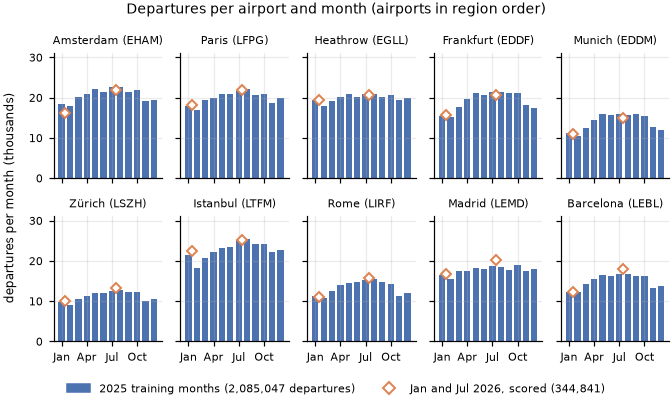

In [3]:
months = np.arange(1, 13)
c25 = tr.groupby(["apt", "month"]).size().unstack(fill_value=0).reindex(index=AIRPORTS, columns=months, fill_value=0)
c26 = rk.groupby(["apt", "month"]).size().unstack(fill_value=0).reindex(index=AIRPORTS, fill_value=0)
tab = pd.DataFrame({"2025 total": c25.sum(axis=1), "Jan 2025": c25[1], "Jul 2025": c25[7],
                    "Jan 2026": c26[1], "Jul 2026": c26[7]})
tab.loc["all"] = tab.sum()
tab["Jan+Jul 2026 / Jan+Jul 2025"] = ((tab["Jan 2026"] + tab["Jul 2026"]) / (tab["Jan 2025"] + tab["Jul 2025"])).round(3)
print(tab.to_string())

fig, axes = plt.subplots(2, 5, figsize=(W, 3.7), sharex=True, sharey=True)
for ax, a in zip(axes.flat, AIRPORTS):
    ax.bar(months, c25.loc[a] / 1e3, color=ps.C_2025, width=0.75)
    ax.plot([1.45, 7.45], c26.loc[a, [1, 7]] / 1e3, "D", mfc="white", mec=ps.C_2026, ms=4.5, mew=1.3, zorder=3, ls="")
    ax.set_title(LABEL[a], fontsize=7.5)
    ax.set_xticks([1, 4, 7, 10], ["Jan", "Apr", "Jul", "Oct"])
    ax.set_ylim(0, 31)
handles = [plt.Rectangle((0, 0), 1, 1, color=ps.C_2025),
           Line2D([], [], marker="D", ls="", mfc="white", mec=ps.C_2026, mew=1.3)]
fig.legend(handles, [f"2025 training months ({len(tr):,} departures)", f"Jan and Jul 2026, scored ({len(rk):,})"],
           loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.01))
fig.supylabel("departures per month (thousands)", fontsize=8)
fig.suptitle("Departures per airport and month (airports in region order)")
fig.tight_layout(rect=(0, 0.06, 1, 1))
ps.save(fig, "fig04_01_departures_per_month")
plt.show()

## Figure 2: the target distribution

**Statement:** the target is not always a taxi time; on a stale record it is the departure delay, up to 36 h. 584
training departures have a target above two hours.

Left: histogram of the 2025 target on logarithmic axes (40 log-spaced bins per decade, so a bin is wider the further
right it sits and the tail looks heavier than a per-minute density would), with the 30 min, 1 h, 2 h and one-day
marks. The 1,105 targets below one minute, 388 of them zero or negative, are left of the axis and not shown. Right: the
share of departures whose target exceeds a value (survival function), from 5 minutes. The cell prints the median, p90,
p99, the share above 30 min and 1 h, the count above 2 h (584, 0.028 %; the stated number), the maximum (131,167 s =
36.4 h) and the non-positive targets.

median 912 s (15.2 min), p90 1,471 s (24.5 min), p99 2,339 s (39.0 min)
mean 991 s; share > 30 min 3.56% (74,167); share > 1 h 0.198% (4,126); count > 2 h 584 (stated: 584); max 131,167 s = 36.4 h
non-positive targets (not on the log axes): 388, min -12 s
targets below 1 min (incl. the non-positive ones; left of the histogram): 1,105


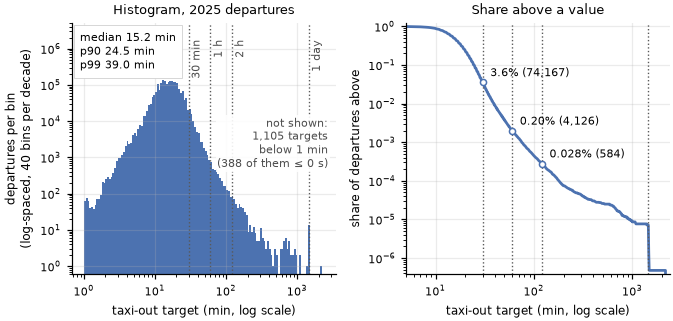

In [4]:
yy = tr["y"]
n = len(yy)
q50, q90, q99 = yy.quantile([0.5, 0.9, 0.99])
n_nonpos = int((yy <= 0).sum())
sh30, sh60 = (yy > 1800).mean(), (yy > 3600).mean()
n2h = int((yy > 7200).sum())
print(f"median {q50:,.0f} s ({q50/60:.1f} min), p90 {q90:,.0f} s ({q90/60:.1f} min), p99 {q99:,.0f} s ({q99/60:.1f} min)")
print(f"mean {yy.mean():,.0f} s; share > 30 min {sh30:.2%} ({int((yy > 1800).sum()):,}); share > 1 h {sh60:.3%} "
      f"({int((yy > 3600).sum()):,}); count > 2 h {n2h:,} (stated: 584); max {yy.max():,.0f} s = {yy.max()/3600:.1f} h")
print(f"non-positive targets (not on the log axes): {n_nonpos:,}, min {yy.min():.0f} s")

pos_min = yy[yy > 0].to_numpy() / 60
print(f"targets below 1 min (incl. the non-positive ones; left of the histogram): {int((yy < 60).sum()):,}")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(W, 3.1))
PER_DEC = 40
bins = 10 ** np.arange(0, np.log10(2400) + 1e-9, 1 / PER_DEC)
ax1.hist(pos_min, bins=bins, color=ps.C_2025)
ax1.set_xscale("log"); ax1.set_yscale("log")
ax1.set_ylim(0.6, 5e6)
ax1.set_xlabel("taxi-out target (min, log scale)"); ax1.set_ylabel(f"departures per bin\n(log-spaced, {PER_DEC} bins per decade)")
ax1.set_title("Histogram, 2025 departures")
ax1.text(0.03, 0.97, f"median {q50/60:.1f} min\np90 {q90/60:.1f} min\np99 {q99/60:.1f} min",
         transform=ax1.transAxes, va="top", fontsize=7.5, bbox=dict(fc="white", ec="0.8", lw=0.5))
ax1.text(0.97, 0.52, f"not shown:\n{int((yy < 60).sum()):,} targets\nbelow 1 min\n({n_nonpos} of them ≤ 0 s)",
         transform=ax1.transAxes, va="center", ha="right", fontsize=7, color="0.3",
         bbox=dict(fc="white", ec="none", alpha=0.9, pad=1))

srt = np.sort(pos_min)
grid = np.logspace(np.log10(5), np.log10(2400), 600)
surv = (len(srt) - np.searchsorted(srt, grid, side="right")) / n
ax2.loglog(grid, surv, color=ps.C_2025, lw=1.8)
ax2.set_xlim(5, 2400)
ax2.set_xlabel("taxi-out target (min, log scale)"); ax2.set_ylabel("share of departures above")
ax2.set_title("Share above a value")
for v, lab in [(30, "30 min"), (60, "1 h"), (120, "2 h"), (1440, "1 day")]:
    for ax in (ax1, ax2):
        ax.axvline(v, color="0.35", ls=":", lw=0.9)
    ax1.text(v * 1.08, ax1.get_ylim()[1] * 0.35, lab, rotation=90, va="top", fontsize=7, color="0.3")
for v, txt in [(30, f"{sh30:.1%} ({int((yy > 1800).sum()):,})"), (60, f"{sh60:.2%} ({int((yy > 3600).sum()):,})"),
               (120, f"{n2h / n:.3%} ({n2h})")]:
    s_at = (len(srt) - np.searchsorted(srt, v, side="right")) / n
    ax2.plot(v, s_at, "o", color=ps.C_2025, mfc="white", ms=4, zorder=3)
    ax2.annotate(txt, (v, s_at), xytext=(5, 4), textcoords="offset points", fontsize=7)
ax2.set_ylim(1 / n * 0.8, 1.2)
fig.tight_layout()
ps.save(fig, "fig04_02_target_distribution")
plt.show()

## Figure 3: taxi-out per airport (targets below one hour)

**Data view.** The airports differ: the stale records sit at Rome, Heathrow and Istanbul, and the same flight's
day-to-day deviation is largest at London (160 s) and Rome (156 s) and smallest at Amsterdam (74 s) and Munich (80 s).
The figure shows the distribution of the target per airport below one hour (box = quartiles, whiskers = 5th to 95th
percentile), sorted by the median of those targets: Heathrow has the longest taxi-out, Zürich and Amsterdam the
shortest, and Rome and Heathrow the widest interquartile ranges (479 s and 472 s, against 299 s at Munich), the same
ordering as the day-to-day deviations, though not the same quantity. The right-hand column gives the median below one
hour and each airport's share of departures of one hour or more, where Rome stands out (1.2 %, four times any other
airport; its tail continues in Figure 4). At Madrid and Barcelona that share is not zero by nature: the source holds
no target above one hour there (see the note at the top), so the column says "capped at 1 h". Rome's median below one
hour is 1,022 s (17.0 min); over all its targets it is 1,025 s.

           n  median all (s)  median <1h (s)  IQR <1h (s)  share >= 1 h  n > 2 h
apt                                                                             
LSZH  134907           711.0           711.0        310.0       0.00019        6
EHAM  247951           742.0           742.0        364.0       0.00033        3
EDDM  167334           774.0           774.0        299.0       0.00035        0
EDDF  230141           837.0           837.0        399.0       0.00032        0
LEBL  179705           906.0           906.0        447.0       0.00001        0
LFPG  239552           954.0           954.0        374.0       0.00166       37
LTFM  272965           963.0           963.0        414.0       0.00291       21
LEMD  212242           985.0           985.0        379.0       0.00000        0
LIRF  160704          1025.0          1022.0        479.0       0.01225      480
EGLL  239546          1319.0          1319.0        472.0       0.00305       37
rows below one hour: 2,080,9

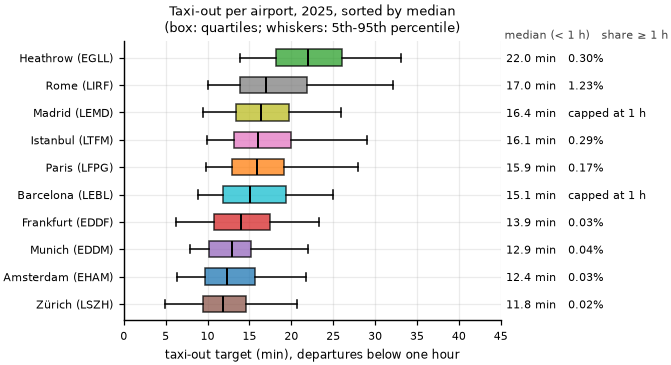

In [5]:
med_all = tr.groupby("apt")["y"].median()
bulk = tr[tr["y"] < 3600]
med_bulk = bulk.groupby("apt")["y"].median()
above1h = tr.groupby("apt")["y"].apply(lambda s: (s >= 3600).mean())
n2h_apt = tr.groupby("apt")["y"].apply(lambda s: int((s > 7200).sum()))
summary = pd.DataFrame({"n": tr.groupby("apt").size(), "median all (s)": med_all, "median <1h (s)": med_bulk,
                        "IQR <1h (s)": bulk.groupby("apt")["y"].quantile(0.75) - bulk.groupby("apt")["y"].quantile(0.25),
                        "share >= 1 h": above1h.round(5), "n > 2 h": n2h_apt}).sort_values("median <1h (s)")
print(summary.to_string())
print(f"rows below one hour: {len(bulk):,} of {len(tr):,} ({len(bulk)/len(tr):.2%})")

order = med_bulk.sort_values().index.tolist()
fig, ax = plt.subplots(figsize=(W, 3.5))
vals = [bulk.loc[bulk["apt"].eq(a), "y"].to_numpy() / 60 for a in order]
bp = ax.boxplot(vals, orientation="horizontal", whis=(5, 95), showfliers=False, patch_artist=True, widths=0.6,
                medianprops=dict(color="black", lw=1.3))
for patch, a in zip(bp["boxes"], order):
    patch.set_facecolor(COL[a]); patch.set_alpha(0.75)
ax.set_yticks(range(1, len(order) + 1), [LABEL[a] for a in order])
ax.set_ylim(0.4, len(order) + 0.6)
ax.set_xlabel("taxi-out target (min), departures below one hour")
ax.set_xlim(0, 45)
right = ax.twinx()
right.set_ylim(ax.get_ylim())
right.set_yticks(range(1, len(order) + 1),
                 [f"{med_bulk[a]/60:.1f} min   " + ("capped at 1 h" if a in CAPPED and MAXY[a] <= 3700 else f"{above1h[a]:.2%}")
                  for a in order])
right.tick_params(axis="y", length=0)
right.grid(False)
right.spines["right"].set_visible(False)
right.text(1.01, 1.0, "median (< 1 h)   share ≥ 1 h", transform=ax.transAxes, fontsize=7, va="bottom", ha="left",
           color="0.25")
ax.set_title("Taxi-out per airport, 2025, sorted by median\n(box: quartiles; whiskers: 5th-95th percentile)")
fig.tight_layout()
ps.save(fig, "fig04_03_taxi_per_airport")
plt.show()

## Figure 4: the tail per airport

**Statement:** under RMSE the non-taxi rows dominate; the stale segment is 98 % at Rome.
Share of each airport's departures whose target exceeds a value, from 10 minutes to 40 hours (log-log); each curve
ends at the airport's largest target (×). Every curve falls steeply after one hour except Rome's, which carries 480 of
the 584 targets above two hours. Two endings are caps in the source data, not thin tails: Madrid's and Barcelona's
curves stop at one hour (largest targets 3,598 s and 3,604 s) and Frankfurt's and Munich's near 115 minutes (6,907 s and
6,899 s); the cell prints each airport's largest target.

           n  > 30 min    > 1 h  n > 2 h  n > 1 day - 1 h  share of all > 2 h  largest target (s)
apt                                                                                              
EHAM  247951    0.0093  0.00033        3                0               0.005             11032.0
LFPG  239552    0.0366  0.00165       37                1               0.063             84240.0
EGLL  239546    0.1059  0.00304       37                0               0.063             11452.0
EDDF  230141    0.0105  0.00032        0                0               0.000              6907.0
EDDM  167334    0.0136  0.00035        0                0               0.000              6899.0
LSZH  134907    0.0076  0.00019        6                1               0.010             87341.0
LTFM  272965    0.0455  0.00291       21                0               0.036             10309.0
LIRF  160704    0.0813  0.01224      480               14               0.822            131167.0
LEMD  212242    0.01

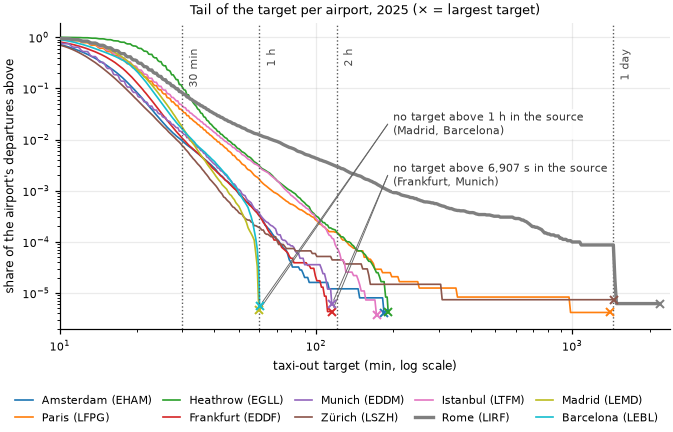

In [6]:
grid = np.logspace(np.log10(10), np.log10(2400), 400)
tail = pd.DataFrame({"n": tr.groupby("apt").size(),
                     "> 30 min": tr.groupby("apt")["y"].apply(lambda s: (s > 1800).mean()).round(4),
                     "> 1 h": tr.groupby("apt")["y"].apply(lambda s: (s > 3600).mean()).round(5),
                     "n > 2 h": n2h_apt, "n > 1 day - 1 h": tr.groupby("apt")["y"].apply(lambda s: int((s > DAY - 3600).sum()))})
tail["share of all > 2 h"] = (tail["n > 2 h"] / tail["n > 2 h"].sum()).round(3)
tail["largest target (s)"] = MAXY
print(tail.reindex(AIRPORTS).to_string())

fig, ax = plt.subplots(figsize=(W, 4.0))
ends = {}
for a in AIRPORTS:
    s = np.sort(tr.loc[tr["apt"].eq(a), "y"].to_numpy() / 60)
    g_ = np.append(grid[grid < s[-1]], s[-1] * (1 - 1e-9))   # the curve runs up to the largest target
    sv = (len(s) - np.searchsorted(s, g_, side="right")) / len(s)
    ax.loglog(g_, sv, color=COL[a], lw=2.2 if a == "LIRF" else 1.1, label=LABEL[a], zorder=3 if a == "LIRF" else 2)
    ax.plot(g_[-1], sv[-1], "x", color=COL[a], ms=5, mew=1.3, zorder=4)
    ends[a] = (g_[-1], sv[-1])
for v, lab in [(30, "30 min"), (60, "1 h"), (120, "2 h"), (1440, "1 day")]:
    ax.axvline(v, color="0.35", ls=":", lw=0.9)
    ax.text(v * 1.06, 0.6, lab, rotation=90, va="top", fontsize=7, color="0.3")
cap1 = [a for a in CAPPED if MAXY[a] <= 3700]
cap2 = [a for a in CAPPED if MAXY[a] > 3700]
for aps, txt, xy in [(cap1, "no target above 1 h in the source\n(" + ", ".join(SHORT[a] for a in cap1) + ")", (190, 2e-2)),
                     (cap2, "no target above " + f"{max(MAXY[a] for a in cap2):,.0f}" + " s in the source\n("
                      + ", ".join(SHORT[a] for a in cap2) + ")", (190, 2e-3))]:
    for a in aps:
        ax.annotate("", ends[a], xytext=xy, textcoords="data",
                    arrowprops=dict(arrowstyle="-", lw=0.6, color="0.4", shrinkA=0, shrinkB=3))
    ax.text(xy[0] * 1.05, xy[1], txt, fontsize=7, va="center", color="0.2",
            bbox=dict(fc="white", ec="none", alpha=0.85, pad=1))
ax.set_xlim(10, 2400)
ax.set_xlabel("taxi-out target (min, log scale)")
ax.set_ylabel("share of the airport's departures above")
ax.set_title("Tail of the target per airport, 2025 (× = largest target)")
fig.legend(*ax.get_legend_handles_labels(), loc="lower center", ncol=5, frameon=False, bbox_to_anchor=(0.5, -0.01),
           columnspacing=1.0, handlelength=1.5)
fig.tight_layout(rect=(0, 0.1, 1, 1))
ps.save(fig, "fig04_04_tail_per_airport")
plt.show()

## Figure 5: what the targets above two hours are

**Statement:** 438 of the 584 training departures above two hours have a target equal to takeoff minus the schedule
within two minutes; fifteen training departures carry the previous day's date (target 86,400 s plus a taxi).

Each departure above two hours is classed as stale (target within 120 s of takeoff minus schedule), wrong-date (target
within an hour of a whole day) or other (a genuinely long taxi, or a block time that matches no clock). One Rome row
(AEZ146R, 15 July 2025, target 87,002 s) is both: its schedule delta is 87,001 s. It is counted with the stale records
(438, as stated) and the bar for wrong-date records holds the other 14, so the stated 438 stale and 15 wrong-date
records overlap by this one row. Rome holds 429 stale records (one of them also wrong-date), 12 wrong-date records and
39 others.

Four airports have no bar at all, and that is not evidence that they have no such records: Madrid and Barcelona have no
target above one hour in the source and Frankfurt and Munich none above 6,907 s, so a wrong-date record (one day plus a
taxi) or a stale record with a delay above the cap cannot appear there. The figure writes the cap in place of a zero.

targets above 2 h: 584 (stated: 584); stale within 120 s: 438 (stated: 438); within 30 min: 507
wrong-date rows (all training): 15 (stated: 15); overlap stale & wrong-date: 1
kind  stale  stale and wrong date  wrong date  other  total
apt                                                        
EHAM      0                     0           0      3      3
LFPG      3                     0           1     33     37
EGLL      5                     0           0     32     37
EDDF      0                     0           0      0      0
EDDM      0                     0           0      0      0
LSZH      0                     0           1      5      6
LTFM      1                     0           0     20     21
LIRF    428                     1          12     39    480
LEMD      0                     0           0      0      0
LEBL      0                     0           0      0      0
kind
stale                   437
stale and wrong date      1
wrong date               14
other           

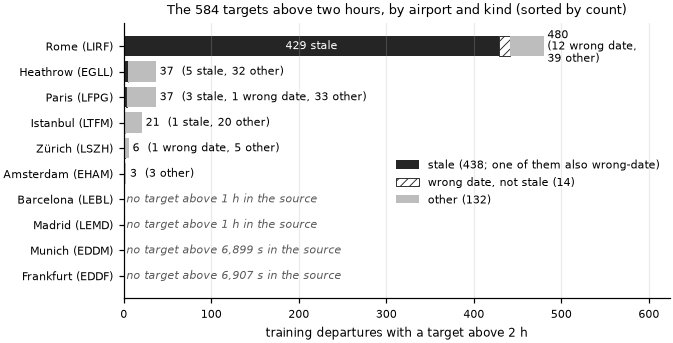

In [7]:
big = tr[tr["y"] > 7200].copy()
print(f"targets above 2 h: {len(big)} (stated: 584); stale within 120 s: {int(big['stale'].sum())} (stated: 438); "
      f"within 30 min: {int(((big['y'] - big['sched_delta']).abs() <= 1800).sum())}")
print(f"wrong-date rows (all training): {int(tr['wrong_date'].sum())} (stated: 15); overlap stale & wrong-date: "
      f"{int((tr['wrong_date'] & tr['stale']).sum())}")
KINDS = ["stale", "stale and wrong date", "wrong date", "other"]
big["kind"] = np.select([big["stale"] & big["wrong_date"], big["stale"], big["wrong_date"]],
                        ["stale and wrong date", "stale", "wrong date"], "other")
ct = big.groupby(["apt", "kind"]).size().unstack(fill_value=0).reindex(index=AIRPORTS, fill_value=0)
ct = ct.reindex(columns=KINDS, fill_value=0)
ct["total"] = ct.sum(axis=1)
print(ct.to_string()); print(ct.sum().to_string())

ct["stale (incl. both)"] = ct["stale"] + ct["stale and wrong date"]
order = ct["total"].sort_values(kind="stable").index.tolist()
fig, ax = plt.subplots(figsize=(W, 3.3))
left = np.zeros(len(order))
n_st, n_wd, n_ot = int(ct["stale (incl. both)"].sum()), int(ct["wrong date"].sum()), int(ct["other"].sum())
for kind, fc, ec, hatch, lab in [
        ("stale (incl. both)", C_STALE, C_STALE, None, f"stale ({n_st}; one of them also wrong-date)"),
        ("wrong date", "white", C_WRONG, ps.WRONG_HATCH, f"wrong date, not stale ({n_wd})"),
        ("other", C_OTHER, C_OTHER, None, f"other ({n_ot})")]:
    v = ct.loc[order, kind].to_numpy()
    ax.barh(range(len(order)), v, left=left, color=fc, hatch=hatch, edgecolor=ec, lw=0.6 if hatch else 0, label=lab)
    left += v
for i, a in enumerate(order):
    r = ct.loc[a]
    if r["total"] == 0:
        ax.text(3, i, CAP_TXT.get(a, "none"), va="center", fontsize=7, color="0.35", style="italic")
    elif a == "LIRF":
        ax.text(r["stale (incl. both)"] / 2, i, f"{r['stale (incl. both)']} stale", va="center", ha="center",
                fontsize=7.5, color="white")
        ax.text(r["total"] + 4, i, f"{r['total']}\n({r['wrong date']} wrong date,\n{r['other']} other)", va="center",
                fontsize=7, linespacing=1.1)
    else:
        parts = [f"{r['stale (incl. both)']} stale" if r["stale (incl. both)"] else "",
                 f"{r['wrong date']} wrong date" if r["wrong date"] else "", f"{r['other']} other" if r["other"] else ""]
        ax.text(r["total"] + 4, i, f"{r['total']}  (" + ", ".join(p for p in parts if p) + ")", va="center", fontsize=7)
ax.set_yticks(range(len(order)), [LABEL[a] for a in order])
ax.set_xlabel("training departures with a target above 2 h")
ax.set_title(f"The {len(big)} targets above two hours, by airport and kind (sorted by count)")
ax.legend(loc="center right", frameon=False, bbox_to_anchor=(1.0, 0.42))
ax.set_xlim(0, ct["total"].max() * 1.3)
ax.grid(axis="y", visible=False)
fig.tight_layout()
ps.save(fig, "fig04_05_tail_anatomy")
plt.show()

## Figure 6: the stale fingerprint and the wrong-date rows

**Statement:** the recorded off-block time is sometimes the scheduled off-block time (a *stale* or fallback record, so
the target is the departure delay, up to 36 h), or an actual time stamped with the wrong date (target one day plus a
taxi). Fifteen training departures carry the previous day's date, twelve of them in the Rome segment.

Left: every training departure with a target of one hour or more, target against takeoff minus schedule (log-log). Stale
records sit on the diagonal (target = schedule delta); wrong-date rows sit at one day whatever their schedule delta.
Of the 4,132 targets of one hour or more, 9 are not drawn: 2 have a schedule delta of zero or less and 7 one below
10 minutes (the axis starts at 10 minutes). On the left, the one row that is both stale and wrong-date is drawn as
wrong-date.

Right: the fifteen wrong-date rows, as the taxi they imply (target minus 86,400 s), filled where the row is in the
untyped, NM-less Rome segment. Fourteen imply an ordinary taxi of 10-33 min. **This differs from the statement's "one
day plus a taxi" for one row:** the Paris record (target 84,240 s) sits 36 min *short* of a day, so it meets the
3,600 s definition without being one day plus a taxi.

targets >= 1 h: 4,132; shown (schedule delta >= 10 min): 4,123; not shown: 2 with delta <= 0 or missing, 7 with 0 < delta < 10 min
kind
other         2239
stale         1878
wrong date      15
wrong-date rows: 15, in the stale-suspect segment: 12 (stated: 15, twelve in the Rome segment)


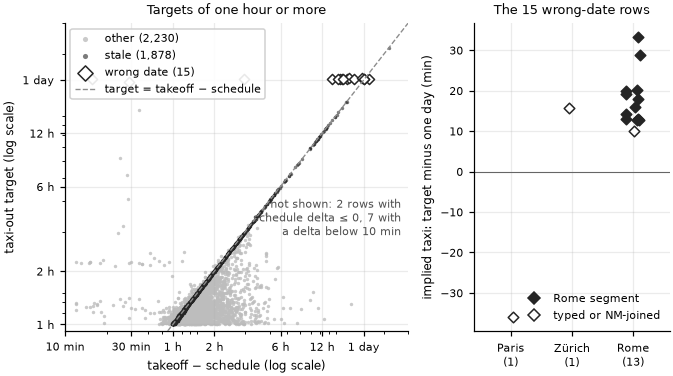

In [8]:
long_ = tr[tr["y"] >= 3600].copy()
long_["kind"] = np.select([long_["wrong_date"], long_["stale"]], ["wrong date", "stale"], "other")
XMIN = 10   # minutes; left edge of the scatter's x axis
shown = long_[long_["sched_delta"] >= XMIN * 60]
n_nonpos_ = int((~(long_["sched_delta"] > 0)).sum())
n_small_ = len(long_) - len(shown) - n_nonpos_
print(f"targets >= 1 h: {len(long_):,}; shown (schedule delta >= {XMIN} min): {len(shown):,}; not shown: "
      f"{n_nonpos_} with delta <= 0 or missing, {n_small_} with 0 < delta < {XMIN} min")
print(long_["kind"].value_counts().to_string())
wd = tr[tr["wrong_date"]].copy()
wd["implied_taxi_s"] = wd["y"] - np.round(wd["y"] / DAY) * DAY
print(f"wrong-date rows: {len(wd)}, in the stale-suspect segment: {int(wd['segment'].sum())} (stated: 15, twelve in the Rome segment)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(W, 3.6), gridspec_kw=dict(width_ratios=[1.75, 1]))
for kind, z in [("other", 1), ("stale", 2), ("wrong date", 3)]:
    g = shown[shown["kind"].eq(kind)]
    lab = f"{kind} ({len(g):,})"
    if kind == "wrong date":
        ax1.scatter(g["sched_delta"] / 60, g["y"] / 60, s=22, marker=ps.WRONG_MARKER, facecolor="white",
                    edgecolor=C_WRONG, lw=1.0, zorder=z, label=lab)
    else:
        ax1.scatter(g["sched_delta"] / 60, g["y"] / 60, s=5, color=C_STALE if kind == "stale" else C_OTHER,
                    alpha=0.6 if kind == "stale" else 0.8, lw=0, zorder=z, label=lab)
lim = (XMIN, 3000)
ax1.plot(lim, lim, color="0.55", lw=0.9, ls="--", zorder=4, label="target = takeoff − schedule")
TT = [(60, "1 h"), (120, "2 h"), (360, "6 h"), (720, "12 h"), (1440, "1 day")]
ax1.set_xscale("log"); ax1.set_yscale("log"); ax1.set_xlim(lim); ax1.set_ylim(55, 3000)
ax1.set_yticks([v for v, _ in TT], [t for _, t in TT]); ax1.yaxis.set_minor_formatter(plt.NullFormatter())
ax1.set_xticks([10, 30] + [v for v, _ in TT], ["10 min", "30 min"] + [t for _, t in TT])
ax1.xaxis.set_minor_formatter(plt.NullFormatter())
ax1.set_xlabel("takeoff − schedule (log scale)"); ax1.set_ylabel("taxi-out target (log scale)")
ax1.set_title("Targets of one hour or more")
ax1.legend(loc="upper left", frameon=True, framealpha=0.9, markerscale=1.5, fontsize=7)
ax1.text(0.98, 0.30, f"not shown: {n_nonpos_} rows with\nschedule delta ≤ 0, {n_small_} with\na delta below {XMIN} min",
         transform=ax1.transAxes, ha="right", va="bottom", fontsize=7, color="0.3")

apts_wd = [a for a in AIRPORTS if (wd["apt"] == a).any()]
rng = np.random.default_rng(0)
for i, a in enumerate(apts_wd):
    g = wd[wd["apt"].eq(a)]
    x = i + rng.uniform(-0.12, 0.12, len(g))
    seg = g["segment"].to_numpy()
    ax2.scatter(x[seg], g["implied_taxi_s"].to_numpy()[seg] / 60, color=C_WRONG, marker=ps.WRONG_MARKER, s=24, zorder=3)
    ax2.scatter(x[~seg], g["implied_taxi_s"].to_numpy()[~seg] / 60, facecolor="white", edgecolor=C_WRONG,
                marker=ps.WRONG_MARKER, s=24, zorder=3)
ax2.axhline(0, color="0.4", lw=0.7)
ax2.set_xticks(range(len(apts_wd)), [f"{SHORT[a]}\n({(wd['apt'] == a).sum()})" for a in apts_wd])
ax2.set_xlim(-0.6, len(apts_wd) - 0.4)
ax2.set_ylabel("implied taxi: target minus one day (min)")
ax2.set_title("The 15 wrong-date rows")
ax2.legend(handles=[Line2D([], [], marker=ps.WRONG_MARKER, ls="", color=C_WRONG, label="Rome segment"),
                    Line2D([], [], marker=ps.WRONG_MARKER, ls="", mfc="white", mec=C_WRONG, label="typed or NM-joined")],
           fontsize=7, loc="lower right", frameon=False)
fig.tight_layout()
ps.save(fig, "fig04_06_stale_fingerprint")
plt.show()

## Figure 7: the stale-suspect segment

**Statement:** stale records concentrate in one segment (no aircraft type and no NM match, 98 % at Rome), where half
the rows are stale; the regime mixture's classifier covers every departure with a candidate stale value (a schedule
delta of 30 min or more, or the Rome segment).

Left: rows of the segment per airport, 2025 training and the 2026 scored months (target-free definition, so it applies
to 2026 too), as dots on a logarithmic axis so that the airports with one to seven rows are visible next to Rome's
1,487; the counts are written next to each pair (a zero has no dot). Right: inside the 2025 segment, target against schedule delta. Two populations:
stale rows on the diagonal, and genuine taxis of 10-40 minutes although the schedule delta is hours. The 19 segment rows
with a schedule delta of zero or less cannot be drawn on the log axis; the legend counts the 1,488 rows drawn.

      2025  2026
apt             
EHAM     1     0
LFPG     5     0
EGLL     0     0
EDDF     0     0
EDDM     0     0
LSZH     7     1
LTFM     7     4
LIRF  1487   383
LEMD     0     0
LEBL     0     0
segment 2025: 1,507 rows, Rome 1,487 = 98.7% (stated: 98 % at Rome); 2026: 388 rows, Rome 383
stale share in the 2025 segment (within 120 s): 48.0%; within 600 s: 48.9% (stated: half)
segment rows with schedule delta >= 30 min: 1,423; segment rows above 2 h: 439 of 584 targets above 2 h; 2026 segment rows with delta > 2 h: 181
segment's share of the training departures: 0.072%
segment rows not shown (schedule delta <= 0): 19


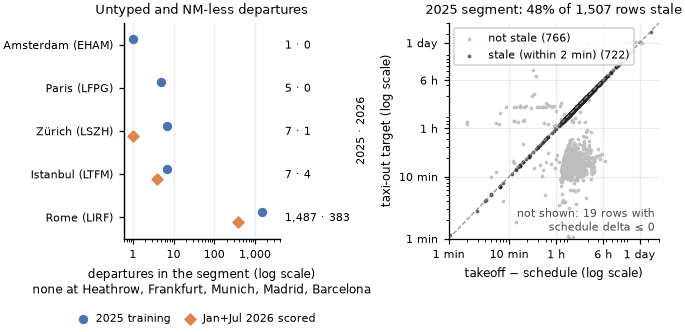

In [9]:
seg25 = tr[tr["segment"]]
seg26 = rk[rk["segment"]]
cnt = pd.DataFrame({"2025": seg25.groupby("apt").size(), "2026": seg26.groupby("apt").size()}).reindex(AIRPORTS).fillna(0).astype(int)
print(cnt.to_string())
print(f"segment 2025: {len(seg25):,} rows, Rome {cnt.loc['LIRF', '2025']:,} = {cnt.loc['LIRF', '2025']/len(seg25):.1%} (stated: 98 % at Rome); "
      f"2026: {len(seg26):,} rows, Rome {cnt.loc['LIRF', '2026']:,}")
st_share = seg25["stale"].mean()
print(f"stale share in the 2025 segment (within 120 s): {st_share:.1%}; within 600 s: "
      f"{((seg25['y'] - seg25['sched_delta']).abs() <= 600).mean():.1%} (stated: half)")
print(f"segment rows with schedule delta >= 30 min: {int((seg25['sched_delta'] >= 1800).sum()):,}; "
      f"segment rows above 2 h: {int((seg25['y'] > 7200).sum())} of {n2h} targets above 2 h; "
      f"2026 segment rows with delta > 2 h: {int((seg26['sched_delta'] > 7200).sum())}")
print(f"segment's share of the training departures: {len(seg25)/len(tr):.3%}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(W - 0.1, 3.4), gridspec_kw=dict(width_ratios=[1, 1.35]))
with_rows = [a for a in AIRPORTS if cnt.loc[a].sum() > 0]
none = [a for a in AIRPORTS if a not in with_rows]
yy_ = np.arange(len(with_rows))
ax1.scatter(cnt.loc[with_rows, "2025"].replace(0, np.nan), yy_ - 0.12, s=26, color=ps.C_2025, label="2025 training", zorder=3)
ax1.scatter(cnt.loc[with_rows, "2026"].replace(0, np.nan), yy_ + 0.12, s=26, marker="D", color=ps.C_2026,
            label="Jan+Jul 2026 scored", zorder=3)
ax1.set_xscale("log")
ax1.set_xlim(0.6, 4000)
ax1.set_yticks(yy_, [LABEL[a] for a in with_rows])
ax1.set_ylim(len(with_rows) - 0.5, -0.5)
r1 = ax1.twinx()
r1.set_ylim(ax1.get_ylim())
r1.set_yticks(yy_, [f"{cnt.loc[a, '2025']:,} · {cnt.loc[a, '2026']:,}" for a in with_rows])
r1.tick_params(axis="y", length=0, labelsize=7); r1.grid(False); r1.spines["right"].set_visible(False)
r1.set_ylabel("2025 · 2026", fontsize=7)
ax1.set_xticks([1, 10, 100, 1000], ["1", "10", "100", "1,000"])
ax1.xaxis.set_minor_formatter(plt.NullFormatter())
ax1.set_xlabel("departures in the segment (log scale)\nnone at " + ", ".join(SHORT[a] for a in none))
ax1.set_title("Untyped and NM-less departures")
ax1.legend(loc="upper center", bbox_to_anchor=(0.45, -0.3), ncols=2, frameon=False, fontsize=7, columnspacing=0.8,
           handletextpad=0.2)
ax1.grid(axis="y", visible=False)

sh = seg25[seg25["sched_delta"] > 0]
for flag, c, lab in [(False, C_OTHER, "not stale"), (True, C_STALE, "stale (within 2 min)")]:
    g = sh[sh["stale"].eq(flag)]
    ax2.scatter(g["sched_delta"] / 60, g["y"] / 60, s=6, color=c, alpha=0.7 if flag else 0.9, lw=0, label=f"{lab} ({len(g):,})")
lim = (1, 3000)
ax2.plot(lim, lim, color="0.55", lw=0.8, ls="--")
TT2 = [(1, "1 min"), (10, "10 min"), (60, "1 h"), (360, "6 h"), (1440, "1 day")]
ax2.set_xscale("log"); ax2.set_yscale("log"); ax2.set_xlim(lim); ax2.set_ylim(1, 3000)
for axis in (ax2.xaxis, ax2.yaxis):
    axis.set_ticks([v for v, _ in TT2], [t for _, t in TT2]); axis.set_minor_formatter(plt.NullFormatter())
ax2.set_xlabel("takeoff − schedule (log scale)"); ax2.set_ylabel("taxi-out target (log scale)")
ax2.set_title(f"2025 segment: {st_share:.0%} of {len(seg25):,} rows stale")
ax2.legend(loc="upper left", frameon=True, framealpha=0.9, fontsize=7)
ax2.text(0.98, 0.02, f"not shown: {len(seg25) - len(sh)} rows with\nschedule delta ≤ 0", transform=ax2.transAxes,
         ha="right", va="bottom", fontsize=7, color="0.3")
print(f"segment rows not shown (schedule delta <= 0): {len(seg25) - len(sh)}")
fig.tight_layout()
ps.save(fig, "fig04_07_stale_segment")
plt.show()

## Figure 8: stale records among delayed flights, by airport and month

**Statement:** stale records occur among delayed flights at Rome (9 % of flights 30 min or more late), Heathrow and
Istanbul; elsewhere they are seasonal (German airports ten times more in winter).

Stale records per 1,000 departures that took off **30 to 60 minutes** after their schedule, per airport and 2025
month. For this view a record counts as stale when the target is within **60 s** of the schedule delta (findings 8.2
explains why the tolerance must be tight among moderately late flights; this is also the tolerance behind findings
10.2's per-month rates). The statement names no tolerance.

**Why 30-60 minutes and not "30 minutes or more".** A stale record's target equals the delay. At Madrid and Barcelona
the source holds no target above one hour and at Frankfurt and Munich none above 6,907 s, so a stale record with a
longer delay cannot appear there, while the flight stays in the denominator: a rate over all flights 30 min or more
late is biased low at those four airports (23-31 % of them are 60 min or more late). Below one hour every airport can
show its stale records, so the 30-60 minute rates are comparable across airports. The cell prints both versions.

The colour scale is a square root (dark cells are compressed), so the numbers in the cells carry the values.

**Against the statement.** Rome's rate among flights 30 min or more late is 8.9 % (60 s tolerance) or 9.7 % (120 s),
as stated (9 %). "German airports ten times more in winter": the December-February rate over the June-August rate is
6.4 times at Frankfurt and 26 times at Munich on the 30-60 minute view (6.8 and 22 times over all flights 30 min or
more late), not ten times.

stale per 1,000 departures 30-60 min late (figure), 60 s tolerance:
month    1     2     3     4     5     6     7     8     9     10    11    12
apt                                                                          
EHAM    6.1   6.4   4.3   0.9   1.2   0.7   0.4   0.9   0.3   0.3   4.0   2.7
LFPG   14.8  16.4   7.8   5.3   6.5   3.7   4.6   4.4   4.2   6.3  14.7  11.7
EGLL   30.1  36.6  33.7  31.8  31.6  32.8  22.5  28.0  24.3  31.7  35.6  28.7
EDDF    8.9   4.4   2.7   1.6   2.0   0.6   0.8   1.3   0.6   1.4   4.8   5.0
EDDM   13.9  11.6   3.8   1.6   1.5   0.3   0.5   0.6   0.3   1.5   9.6  11.2
LSZH    4.9   3.6   0.0   1.2   0.3   0.9   1.5   0.0   0.8   0.0   1.4   1.6
LTFM   17.2  42.6  27.1  20.2  31.2  13.3  22.2   9.6   7.9  15.4  29.3  13.7
LIRF   77.3  92.4  91.1  93.9  83.2  75.7  89.7  92.5  77.6  93.0  87.5  98.2
LEMD    6.3   8.9   8.3   6.5   4.1   4.1   2.6   6.0   5.2   5.7   6.1   5.8
LEBL    3.6   3.6   2.9   8.4   6.7   8.4  31.4  24.5  20.4   7.9   7.5   

  overall %, 120 s: {'EHAM': 0.39, 'LFPG': 1.35, 'EGLL': 5.65, 'EDDF': 0.43, 'EDDM': 0.75, 'LSZH': 0.25, 'LTFM': 3.78, 'LIRF': 9.71, 'LEMD': 1.0, 'LEBL': 1.62}
stale per 1,000 departures >= 30 min late (the statement's population), 60 s tolerance:
month    1      2     3     4     5     6     7     8     9     10    11    12
apt                                                                           
EHAM    3.9    4.7   3.4   0.9   0.9   0.5   0.3   0.7   0.2   0.2   2.9   1.9
LFPG   10.1   12.4   6.2   4.4   5.1   2.8   3.2   3.4   3.0   4.9  10.3   8.1
EGLL   22.3   30.1  26.9  27.0  25.8  25.5  16.3  22.8  17.8  25.6  29.4  21.9
EDDF    6.7    3.5   2.1   1.3   1.5   0.5   0.6   1.0   0.4   1.2   4.0   3.9
EDDM   10.3    9.1   3.2   1.3   1.2   0.4   0.4   0.4   0.2   1.2   7.7   8.4
LSZH    4.2    3.0   0.0   1.0   0.3   0.6   1.1   0.0   0.6   0.0   1.2   1.3
LTFM   12.3   30.4  20.9  15.7  23.9  10.2  16.1   7.1   5.9  11.5  22.5   9.5
LIRF   78.1  102.6  96.7  91.9  83.7  80.

  winter (Dec-Feb) / summer (Jun-Aug) ratio, >= 30 min late (the statement's population): {'EHAM': 7.0, 'LFPG': 3.2, 'EGLL': 1.1, 'EDDF': 6.8, 'EDDM': 22.3, 'LSZH': 4.7, 'LTFM': 1.5, 'LIRF': 1.1, 'LEMD': 1.7, 'LEBL': 0.3}
  overall %, 60 s: {'EHAM': 0.15, 'LFPG': 0.58, 'EGLL': 2.35, 'EDDF': 0.18, 'EDDM': 0.29, 'LSZH': 0.09, 'LTFM': 1.46, 'LIRF': 8.92, 'LEMD': 0.41, 'LEBL': 0.9}
  overall %, 120 s: {'EHAM': 0.29, 'LFPG': 0.99, 'EGLL': 4.44, 'EDDF': 0.33, 'EDDM': 0.59, 'LSZH': 0.2, 'LTFM': 2.84, 'LIRF': 9.65, 'LEMD': 0.73, 'LEBL': 1.11}
share of the >= 30 min late flights that are >= 60 min late: {'EHAM': 0.289, 'LFPG': 0.288, 'EGLL': 0.236, 'EDDF': 0.241, 'EDDM': 0.232, 'LSZH': 0.224, 'LTFM': 0.274, 'LIRF': 0.284, 'LEMD': 0.266, 'LEBL': 0.314}


departures 30-60 min late per cell (min per airport): {'EHAM': 3980, 'LFPG': 3976, 'EGLL': 4268, 'EDDF': 2949, 'EDDM': 1469, 'LSZH': 1652, 'LTFM': 2398, 'LIRF': 2099, 'LEMD': 2932, 'LEBL': 1932}


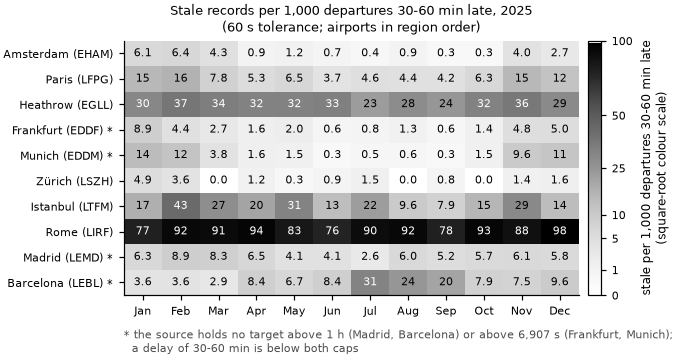

In [10]:
lateall = tr[tr["sched_delta"] >= 1800].copy()
lateall["st60"] = (lateall["y"] - lateall["sched_delta"]).abs() <= 60
late = lateall[lateall["sched_delta"] < 3600]            # 30-60 min late: comparable at every airport (source caps)
win_m, sum_m = [12, 1, 2], [6, 7, 8]
for name, L in (("30-60 min late (figure)", late), (">= 30 min late (the statement's population)", lateall)):
    r_ = (L.groupby(["apt", "month"])["st60"].mean().unstack() * 1000).reindex(index=AIRPORTS, columns=months)
    print(f"stale per 1,000 departures {name}, 60 s tolerance:"); print(r_.round(1).to_string())
    ratio = (L[L["month"].isin(win_m)].groupby("apt")["st60"].mean()
             / L[L["month"].isin(sum_m)].groupby("apt")["st60"].mean()).reindex(AIRPORTS)
    print(f"  winter (Dec-Feb) / summer (Jun-Aug) ratio, {name}:", ratio.round(1).to_dict())
    print(f"  overall %, 60 s:", (L.groupby("apt")["st60"].mean() * 100).round(2).reindex(AIRPORTS).to_dict())
    print(f"  overall %, 120 s:", (L.groupby("apt")["stale"].mean() * 100).round(2).reindex(AIRPORTS).to_dict())
print("share of the >= 30 min late flights that are >= 60 min late:",
      (lateall["sched_delta"] >= 3600).groupby(lateall["apt"]).mean().round(3).reindex(AIRPORTS).to_dict())
rate = (late.groupby(["apt", "month"])["st60"].mean().unstack() * 1000).reindex(index=AIRPORTS, columns=months)
nlate = late.groupby(["apt", "month"]).size().unstack().reindex(index=AIRPORTS, columns=months)
print("departures 30-60 min late per cell (min per airport):", nlate.min(axis=1).to_dict())

fig, ax = plt.subplots(figsize=(W, 3.5))
im = ax.imshow(rate.to_numpy(), cmap="Greys", norm=PowerNorm(gamma=0.5, vmin=0, vmax=float(rate.max().max())), aspect="auto")
for i in range(rate.shape[0]):
    for j in range(rate.shape[1]):
        v = rate.iat[i, j]
        ax.text(j, i, f"{v:.0f}" if v >= 10 else f"{v:.1f}", ha="center", va="center", fontsize=7,
                color="white" if v > 30 else "black")
ax.set_xticks(range(12), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_yticks(range(len(AIRPORTS)), [LABEL[a] + (" *" if a in CAPPED else "") for a in AIRPORTS])
ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
cb.set_label("stale per 1,000 departures 30-60 min late\n(square-root colour scale)")
cb.set_ticks([0, 1, 5, 10, 25, 50, 100])
ax.set_title("Stale records per 1,000 departures 30-60 min late, 2025\n(60 s tolerance; airports in region order)")
ax.text(0, -0.13, "* the source holds no target above 1 h (Madrid, Barcelona) or above 6,907 s (Frankfurt, Munich);\n"
        "  a delay of 30-60 min is below both caps", transform=ax.transAxes, fontsize=7, color="0.3", va="top")
fig.tight_layout()
ps.save(fig, "fig04_08_stale_rate_heatmap")
plt.show()

## Figure 9: NM's clock against the target

**Statement:** NM's actual off-block time (`AOBT_3_flt`) is published for the 2026 departures; only the airport's
off-block time is blanked, and the task is to infer that one time stamp from the others. The strongest single input is
takeoff minus NM's actual off-block. At Heathrow NM's off-block precedes the on-stand de-icing.

Left: the target against NM's proxy (takeoff − `AOBT_3`) for departures with both below one hour (hexbin, log counts).
Right: per airport, the median and interquartile range of proxy minus target, with the share of rows where the two
agree within a minute (sorted by the median). The two clocks differ by a per-airport offset (findings 7.2: Istanbul
+296 s, Rome −118 s, Amsterdam +107 s; only 9-26 % of rows within a minute), which is why the proxy is a strong input
and not a copy of the target. The Pearson correlation inside the hexbin window is 0.58.

      n with AOBT_3  median proxy - target (s)    q25    q75  MAD (s)  within 60 s
apt                                                                               
EHAM         243867                      107.0   -3.0  241.0    120.0        0.237
LFPG         235779                       -4.0 -182.0  123.0    174.0        0.219
EGLL         238132                       54.0 -124.0  234.0    178.0        0.194
EDDF         228185                       87.0  -44.0  197.0    119.0        0.210
EDDM         166324                       -2.0 -177.0  117.0    122.0        0.257
LSZH         132616                      -33.0 -183.0   96.0    139.0        0.242
LTFM         269320                      296.0   57.0  479.0    189.0        0.087
LIRF         159216                     -118.0 -360.0   61.0    186.0        0.186
LEMD         211295                        2.0 -122.0  120.0    121.0        0.262
LEBL         177843                      -54.0 -179.0   65.0    124.0        0.264


rows with AOBT_3: 2,062,577 of 2,085,047; in the hexbin window: 2,056,544; Pearson r there: 0.581


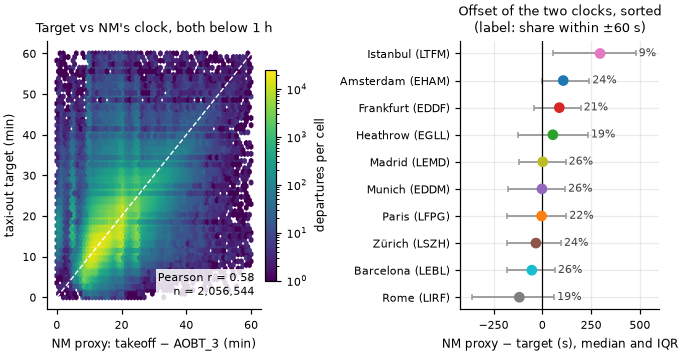

In [11]:
nm = tr[tr["proxy"].notna()].copy()
nm["diff"] = nm["proxy"] - nm["y"]
g = nm.groupby("apt")["diff"]
clk = pd.DataFrame({"n with AOBT_3": g.size(), "median proxy - target (s)": g.median(),
                    "q25": g.quantile(0.25), "q75": g.quantile(0.75),
                    "MAD (s)": g.apply(lambda s: (s - s.median()).abs().median()),
                    "within 60 s": g.apply(lambda s: (s.abs() <= 60).mean()).round(3)}).reindex(AIRPORTS)
print(clk.to_string())
inb = nm[(nm["y"] > 0) & (nm["y"] < 3600) & (nm["proxy"] > 0) & (nm["proxy"] < 3600)]
r_hex = np.corrcoef(inb["proxy"], inb["y"])[0, 1]
print(f"rows with AOBT_3: {len(nm):,} of {len(tr):,}; in the hexbin window: {len(inb):,}; Pearson r there: {r_hex:.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(W, 3.4), gridspec_kw=dict(width_ratios=[1.15, 1]))
hb = ax1.hexbin(inb["proxy"] / 60, inb["y"] / 60, gridsize=60, bins="log", cmap="viridis", mincnt=1, extent=(0, 60, 0, 60))
ax1.plot([0, 60], [0, 60], color="white", lw=0.9, ls="--")
ax1.set_xlabel("NM proxy: takeoff − AOBT_3 (min)"); ax1.set_ylabel("taxi-out target (min)")
ax1.set_title("Target vs NM's clock, both below 1 h")
ax1.text(0.97, 0.04, f"Pearson r = {r_hex:.2f}\nn = {len(inb):,}", transform=ax1.transAxes, ha="right", va="bottom",
         fontsize=7.5, color="black", bbox=dict(fc="white", ec="none", alpha=0.85, pad=1.5))
ax1.grid(False)
cb = fig.colorbar(hb, ax=ax1, fraction=0.046, pad=0.02); cb.set_label("departures per cell")

order = clk["median proxy - target (s)"].sort_values().index.tolist()
yp = np.arange(len(order))
med = clk.loc[order, "median proxy - target (s)"].to_numpy()
ax2.errorbar(med, yp, xerr=[med - clk.loc[order, "q25"].to_numpy(), clk.loc[order, "q75"].to_numpy() - med],
             fmt="none", ecolor="0.6", lw=1.2, capsize=2)
ax2.scatter(med, yp, color=[COL[a] for a in order], s=36, zorder=3)
ax2.axvline(0, color="black", lw=0.8)
for i, a in enumerate(order):
    ax2.text(clk.loc[a, "q75"] + 15, i, f"{clk.loc[a, 'within 60 s']:.0%}", va="center", fontsize=7, color="0.25")
ax2.set_yticks(yp, [LABEL[a] for a in order])
ax2.set_xlabel("NM proxy − target (s), median and IQR")
ax2.set_title("Offset of the two clocks, sorted\n(label: share within ±60 s)")
ax2.set_xlim(-420, 600)
fig.tight_layout()
ps.save(fig, "fig04_09_nm_clock_vs_target")
plt.show()

## Figure 10: NM's off-block clock is quantised at some airports

**Data view** (findings 7.2: "a quantised, default `AOBT_3` at LTFM/EDDM/LSZH (67/52/57 % of rows on three minute
values) … the modes are the unimpeded taxi, not a default"). `AOBT_3` is recorded on whole minutes, so the proxy
counted in one-minute bins (floor) shows how concentrated it is: at Istanbul, Munich and Zürich three one-minute
values hold more than half of the rows (67 / 52 / 57 %), while the target's own three most frequent minutes hold only
26 / 32 / 32 %. Barcelona is as concentrated (60 %, target 25 %) although findings 7.2 does not name it, so it is drawn
as the fourth panel. The cell prints the same shares for all ten airports.

     proxy top-3 minutes  proxy share on top 3  target share on its top 3  AOBT_3 on whole minute
apt                                                                                              
EHAM        [10, 11, 12]                 0.293                      0.275                   0.838
LFPG        [12, 13, 14]                 0.312                      0.261                   0.997
EGLL        [20, 21, 22]                 0.199                      0.210                   1.000
EDDF        [13, 14, 15]                 0.325                      0.241                   0.990
EDDM        [10, 11, 12]                 0.522                      0.324                   0.999
LSZH         [9, 11, 12]                 0.569                      0.322                   1.000
LTFM        [19, 20, 24]                 0.666                      0.258                   0.989
LIRF        [13, 14, 15]                 0.382                      0.222                   0.996
LEMD        [15, 16,

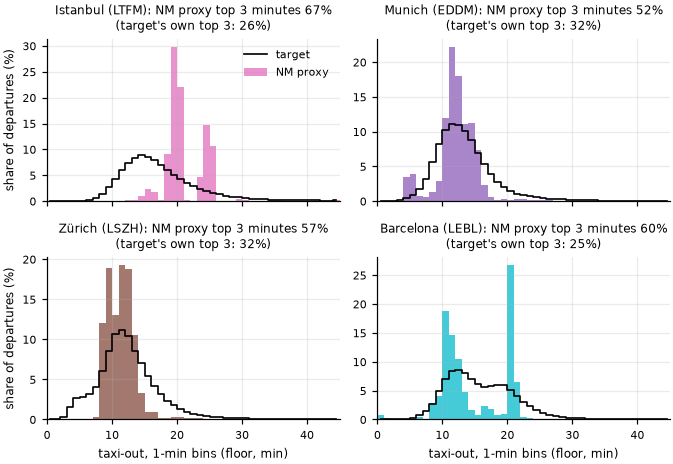

In [12]:
nm["pm"] = np.floor(nm["proxy"] / 60)
nm["ym"] = np.floor(nm["y"] / 60)
rows = []
for a in AIRPORTS:
    x = nm[nm["apt"].eq(a)]
    vp, vy = x["pm"].value_counts(), x["ym"].value_counts()
    rows.append({"apt": a, "proxy top-3 minutes": sorted(int(v) for v in vp.index[:3]),
                 "proxy share on top 3": round(vp.iloc[:3].sum() / len(x), 3),
                 "target share on its top 3": round(vy.iloc[:3].sum() / len(x), 3),
                 "AOBT_3 on whole minute": round(float((x["AOBT_3_flt"].dt.second == 0).mean()), 3)})
qt = pd.DataFrame(rows).set_index("apt")
print(qt.to_string())

sel = ["LTFM", "EDDM", "LSZH", "LEBL"]
fig, axes = plt.subplots(2, 2, figsize=(W, 4.4), sharex=True)
edges = np.arange(0, 46)
for ax, a in zip(axes.flat, sel):
    x = nm[nm["apt"].eq(a)]
    hp = np.histogram(x["pm"], bins=edges)[0] / len(x) * 100
    hy = np.histogram(x["ym"], bins=edges)[0] / len(x) * 100
    ax.bar(edges[:-1] + 0.5, hp, width=1.0, color=COL[a], alpha=0.8, label="NM proxy")
    ax.step(edges[:-1] + 0.5, hy, where="mid", color="black", lw=1.1, label="target")
    ax.set_title(f"{LABEL[a]}: NM proxy top 3 minutes {qt.loc[a, 'proxy share on top 3']:.0%}\n"
                 f"(target's own top 3: {qt.loc[a, 'target share on its top 3']:.0%})", fontsize=8)
    ax.set_xlim(0, 45)
for ax in axes[1]:
    ax.set_xlabel("taxi-out, 1-min bins (floor, min)")
for ax in axes[:, 0]:
    ax.set_ylabel("share of departures (%)")
axes[0, 0].legend(frameon=False)
fig.tight_layout()
ps.save(fig, "fig04_10_aobt3_quantisation")
plt.show()

## Figure 11: the NM join window

**Statement:** a movement carries NM data only when the airport's off-block time lies within 3,606 s of NM's last
known off-block time: `LOBT_flt − BLOCK_TIME_UTC_mvt ∈ [−3,606, +3,606]` s on every NM-matched departure, without
exception for all 2,062,577 matched 2025 departures. It turns into a hard bound on the target of 98.5 % of the scored
departures.

Left: LOBT minus the airport's block time on every 2025 departure that carries `LOBT_flt` (60 s bins, log counts), with
the ±3,606 s bound. These are the "matched" departures: 2,062,577 carry `LOBT_flt`; 46 more have an NM
flight id without `LOBT_flt` and are not drawn. Right: share of departures carrying `LOBT_flt` per airport (region
order), 2025 against the 2026 scored months.

2025 departures with LOBT: 2,062,577 (stated: 2,062,577); min -3,606 s, max 3,606 s; outside ±3,606 s: 0
2025 departures with an NM flight id: 2,062,623; with LOBT but no NM id: 0
share within ±600 s: 69.6%; beyond ±3,000 s: 0.515%
         min     max   count
apt                         
EHAM -3602.0  3548.0  243867
LFPG -3606.0  3604.0  235779
EGLL -3606.0  3606.0  238132
EDDF -3605.0  3593.0  228185
EDDM -3606.0  3485.0  166324
LSZH -3602.0  3601.0  132616
LTFM -3606.0  3605.0  269320
LIRF -3606.0  3606.0  159216
LEMD -3606.0  3598.0  211295
LEBL -3606.0  3604.0  177843


       2025   2026
apt               
EHAM  98.35  96.84
LFPG  98.42  98.16
EGLL  99.41  99.38
EDDF  99.15  98.84
EDDM  99.40  99.08
LSZH  98.30  97.15
LTFM  98.66  98.48
LIRF  99.07  98.58
LEMD  99.55  99.36
LEBL  98.96  98.53
overall share with LOBT: 2025 98.92%, 2026 98.47% (339,551 of 344,841; stated: 98.5 %)


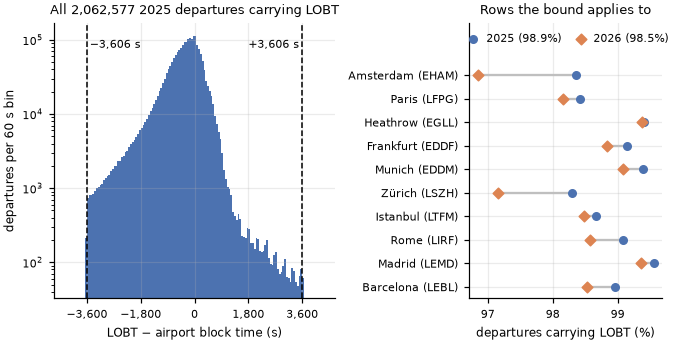

In [13]:
lb = tr["lobt_minus_block"].dropna()
print(f"2025 departures with LOBT: {len(lb):,} (stated: 2,062,577); min {lb.min():,.0f} s, max {lb.max():,.0f} s; "
      f"outside ±3,606 s: {int((lb.abs() > 3606).sum())}")
print(f"2025 departures with an NM flight id: {int(tr['FLIGHT_ID_mvt'].notna().sum()):,}; with LOBT but no NM id: "
      f"{int((tr['has_lobt'] & tr['unjoined']).sum())}")
print(f"share within ±600 s: {(lb.abs() <= 600).mean():.1%}; beyond ±3,000 s: {(lb.abs() > 3000).mean():.3%}")
edge = tr.groupby("apt")["lobt_minus_block"].agg(["min", "max", "count"]).reindex(AIRPORTS)
print(edge.to_string())
sh = pd.DataFrame({"2025": tr.groupby("apt")["has_lobt"].mean(), "2026": rk.groupby("apt")["has_lobt"].mean()}).reindex(AIRPORTS)
print((sh * 100).round(2).to_string())
print(f"overall share with LOBT: 2025 {tr['has_lobt'].mean():.2%}, 2026 {rk['has_lobt'].mean():.2%} "
      f"({int(rk['has_lobt'].sum()):,} of {len(rk):,}; stated: 98.5 %)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(W, 3.3), gridspec_kw=dict(width_ratios=[1.45, 1]))
bins = np.arange(-4200, 4201, 60)
ax1.hist(lb, bins=bins, color=ps.C_2025)
ax1.set_yscale("log")
for v in (-3606, 3606):
    ax1.axvline(v, color="black", lw=1.0, ls="--")
ax1.text(3606 - 100, ax1.get_ylim()[1] * 0.6, "+3,606 s", fontsize=7, va="top", ha="right")
ax1.text(-3606 + 100, ax1.get_ylim()[1] * 0.6, "−3,606 s", fontsize=7, va="top", ha="left")
ax1.set_xlim(-4700, 4700)
ax1.set_xticks([-3600, -1800, 0, 1800, 3600], ["−3,600", "−1,800", "0", "1,800", "3,600"])
ax1.set_xlabel("LOBT − airport block time (s)")
ax1.set_ylabel("departures per 60 s bin")
ax1.set_title(f"All {len(lb):,} 2025 departures carrying LOBT")

yp = np.arange(len(AIRPORTS))
ax2.hlines(yp, sh["2025"] * 100, sh["2026"] * 100, color="0.75", lw=1.5)
ax2.scatter(sh["2025"] * 100, yp, color=ps.C_2025, s=24, label=f"2025 ({tr['has_lobt'].mean():.1%})", zorder=3)
ax2.scatter(sh["2026"] * 100, yp, color=ps.C_2026, s=24, marker="D", label=f"2026 ({rk['has_lobt'].mean():.1%})", zorder=3)
ax2.set_yticks(yp, [LABEL[a] for a in AIRPORTS])
ax2.set_ylim(len(AIRPORTS) - 0.5, -2.2)
ax2.set_xlabel("departures carrying LOBT (%)")
ax2.set_title("Rows the bound applies to")
ax2.legend(loc="upper center", ncol=2, frameon=False, fontsize=7, handletextpad=0.2, columnspacing=0.8)
fig.tight_layout()
ps.save(fig, "fig04_11_join_window")
plt.show()

## Figure 12: taxi-out by local hour and by month

**Data view**: the hour and the calendar enter the model (the calendar among the takeoff-anchored inputs), and the
seasonal holdout exists because January and July differ from the rest of the year. No number is stated for this view.

Each cell is the mean target of the departures below one hour in that airport-hour (top, local hour of takeoff) or
airport-month (bottom), **minus the airport's own mean** over the year, in minutes, so that the ten airports' profiles
can be read on one colour scale. Hours with fewer than 300 departures in the year are left blank. The airport's mean
is written next to its name. The bottom panel writes each deviation in its cell; the holdout months are framed.

The mean of the bulk is used rather than the median because at five airports (EDDM, EGLL, LFPG, LIRF, LTFM) the target
is recorded to the minute: every target lies within 12 s of a whole minute, so a median jumps between minute values
(Istanbul's monthly median alternates between about 957 s and 1,012 s). The cell prints that check and the medians.

share of targets within 12 s of a whole minute: {'EHAM': 0.422, 'LFPG': 1.0, 'EGLL': 1.0, 'EDDF': 0.417, 'EDDM': 1.0, 'LSZH': 0.419, 'LTFM': 1.0, 'LIRF': 1.0, 'LEMD': 0.417, 'LEBL': 0.415}
median target by month (s):


month      1       2       3       4       5       6       7       8       9       10      11      12
apt                                                                                                  
EHAM    727.0   760.0   807.0   821.0   812.0   677.0   751.0   731.0   698.0   695.0   715.0   744.0
LFPG    907.0   900.0   893.0   905.0   949.0   895.0   962.0  1015.0  1015.0  1012.0  1013.0   953.0
EGLL   1261.0  1268.0  1317.0  1267.0  1316.0  1327.0  1373.0  1321.0  1372.0  1329.0  1319.0  1323.0
EDDF    825.0   814.0   801.5   821.0   834.0   841.0   840.0   839.0   854.0   852.0   853.0   852.5
EDDM    729.0   728.0   723.0   769.0   769.0   773.0   780.0   775.0   781.0   779.0   775.0   833.0
LSZH    705.0   700.0   705.0   714.0   713.0   719.0   720.0   715.0   710.0   707.0   709.0   714.0
LTFM    967.0  1009.0   957.0   955.0  1014.0   951.0  1012.0   959.0   949.0  1014.0  1015.0   910.0
LIRF   1009.0   959.0  1013.0  1030.5  1032.0  1082.0  1132.0  1071.0  1031.0  103

mean target below 1 h by month (min):
month     1      2      3      4      5      6      7      8      9      10     11     12
apt                                                                                      
EHAM   13.37  13.64  14.11  14.04  13.81  11.94  13.10  12.76  12.21  12.03  12.77  13.10
LFPG   17.58  16.56  15.48  15.98  16.47  15.62  17.02  17.56  17.57  17.42  18.21  17.12
EGLL   21.96  21.91  22.52  21.78  22.37  22.80  23.36  22.65  23.30  22.81  22.48  22.75
EDDF   14.71  14.10  13.81  13.97  14.27  14.41  14.44  14.20  14.53  14.41  14.87  14.80
EDDM   14.48  13.89  12.77  12.81  12.81  13.08  13.38  13.19  13.45  13.37  13.96  15.74
LSZH   12.88  12.40  12.22  12.19  12.24  12.32  12.37  12.26  12.12  12.05  12.67  12.61
LTFM   17.32  19.02  16.92  16.99  17.97  16.61  18.17  17.04  16.43  17.94  17.94  16.49
LIRF   17.50  17.00  17.83  18.88  18.92  19.48  20.48  19.32  18.87  18.97  17.17  17.59
LEMD   16.43  16.37  17.38  16.63  16.62  17.06  17.20  17.27 

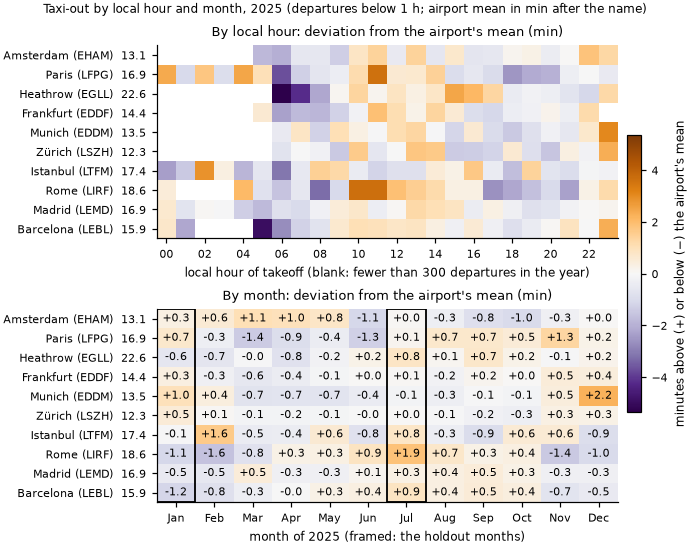

In [14]:
off_min = ((tr["y"] + 30) % 60) - 30
print("share of targets within 12 s of a whole minute:", off_min.abs().le(12).groupby(tr["apt"]).mean().round(3).reindex(AIRPORTS).to_dict())
print("median target by month (s):"); print(tr.groupby(["apt", "month"])["y"].median().unstack().reindex(AIRPORTS).to_string())
bulk = tr[(tr["y"] > 0) & (tr["y"] < 3600)]
hr = bulk.groupby(["apt", "hour_local"])["y"].agg(["mean", "size"])
mo = bulk.groupby(["apt", "month"])["y"].mean().unstack().reindex(index=AIRPORTS, columns=months)
print("mean target below 1 h by month (min):"); print((mo / 60).round(2).to_string())
peak = {a: int(hr.loc[a][hr.loc[a]["size"] >= 300]["mean"].idxmax()) for a in AIRPORTS}
print("local hour with the highest mean (hours with >= 300 departures):", peak)
print("month-to-month range of the mean (min):", ((mo.max(axis=1) - mo.min(axis=1)) / 60).round(2).to_dict())
print("July minus January (min):", ((mo[7] - mo[1]) / 60).round(2).to_dict())

hours = np.arange(24)
apt_mean = bulk.groupby("apt")["y"].mean().reindex(AIRPORTS)
hm = (hr["mean"].where(hr["size"] >= 300).unstack().reindex(index=AIRPORTS, columns=hours)
      .sub(apt_mean, axis=0) / 60)
md_ = mo.sub(apt_mean, axis=0) / 60
print("airport mean below 1 h (min):", (apt_mean / 60).round(2).to_dict())
print("hour deviation range per airport (min):", (hm.max(axis=1) - hm.min(axis=1)).round(2).to_dict())
vmax = float(np.nanmax(np.abs(np.r_[hm.to_numpy().ravel(), md_.to_numpy().ravel()])))
norm = TwoSlopeNorm(vcenter=0, vmin=-vmax, vmax=vmax)
cmap = plt.get_cmap("PuOr_r").copy(); cmap.set_bad("white")
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(W, 5.0), layout="constrained")
ylabels = [f"{LABEL[a]}  {apt_mean[a] / 60:.1f}" for a in AIRPORTS]
im = ax1.imshow(np.ma.masked_invalid(hm.to_numpy()), cmap=cmap, norm=norm, aspect="auto")
ax1.set_xticks(range(0, 24, 2), [f"{h:02d}" for h in range(0, 24, 2)])
ax1.set_xlabel("local hour of takeoff (blank: fewer than 300 departures in the year)")
ax1.set_title("By local hour: deviation from the airport's mean (min)")
im2 = ax2.imshow(md_.to_numpy(), cmap=cmap, norm=norm, aspect="auto")
for i in range(md_.shape[0]):
    for j in range(md_.shape[1]):
        v = md_.iat[i, j]
        ax2.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=7,
                 color="white" if abs(v) > 0.6 * vmax else "black")
for m_ in (1, 7):
    ax2.add_patch(plt.Rectangle((m_ - 1.5, -0.5), 1, len(AIRPORTS), fill=False, ec="black", lw=1.2))
ax2.set_xticks(range(12), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax2.set_xlabel("month of 2025 (framed: the holdout months)")
ax2.set_title("By month: deviation from the airport's mean (min)")
for ax in (ax1, ax2):
    ax.set_yticks(range(len(AIRPORTS)), ylabels)
    ax.grid(False)
cb = fig.colorbar(im, ax=[ax1, ax2], fraction=0.03, pad=0.02)
cb.set_label("minutes above (+) or below (−) the airport's mean")
fig.suptitle("Taxi-out by local hour and month, 2025 (departures below 1 h; airport mean in min after the name)",
             fontsize=8)
ps.save(fig, "fig04_12_hour_and_month")
plt.show()

## Figure 13: the holdout against the scored months

**Statement:** the seasonal holdout (fit on the other ten months of 2025, validate on January and July 2025) is the
seasonal twin of the test months, and the default. Left: departures per airport in January and July 2025 (holdout)
and January and July 2026 (scored). Right: the 2026 target is hidden, so the two years are compared through NM's
proxy, which is known in both years and measured the same way: its median per airport in the 2025 holdout and in
2026, with the 2025 holdout target's median for reference. Findings 10.2 reports the proxy's median as unchanged
between the years; per airport it is unchanged within 6 s at eight airports, while Amsterdam (+56 s) and Frankfurt
(+38 s) moved in 2026, the airports of January 2026's cold spell. The cell also prints the pooled per-minute
distributions, which overlap almost exactly and are therefore not drawn.

      holdout 2025  scored 2026  2026 / 2025  proxy median 2025 (s)  proxy median 2026 (s)  target median 2025 (s)
apt                                                                                                               
EHAM         40949        38182        0.932                  862.0                  918.0                   739.0
LFPG         39612        39872        1.007                  899.0                  904.5                   954.0
EGLL         40210        39840        0.991                 1325.0                 1319.0                  1317.0
EDDF         36830        36317        0.986                  900.0                  938.0                   833.0
EDDM         27091        25966        0.958                  721.0                  719.0                   775.0
LSZH         22346        23150        1.036                  678.5                  673.0                   714.0
LTFM         46539        47581        1.022                 1201.0             

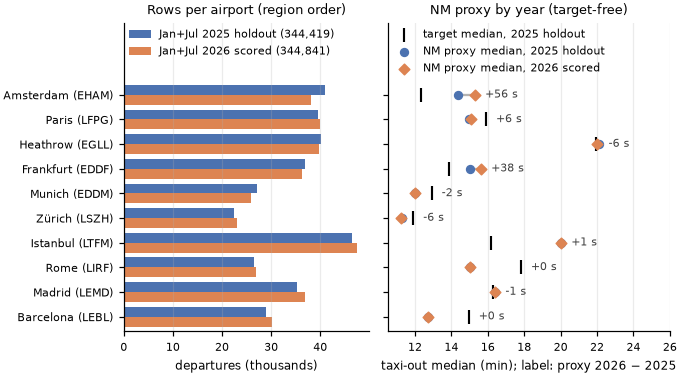

In [15]:
ho = tr[tr["holdout"]]
cmp_ = pd.DataFrame({"holdout 2025": ho.groupby("apt").size(), "scored 2026": rk.groupby("apt").size()}).reindex(AIRPORTS)
cmp_["2026 / 2025"] = (cmp_["scored 2026"] / cmp_["holdout 2025"]).round(3)
cmp_["proxy median 2025 (s)"] = ho.groupby("apt")["proxy"].median()
cmp_["proxy median 2026 (s)"] = rk.groupby("apt")["proxy"].median()
cmp_["target median 2025 (s)"] = ho.groupby("apt")["y"].median()
print(cmp_.to_string())
print(f"holdout {len(ho):,} rows, scored {len(rk):,} rows; proxy median holdout {ho['proxy'].median():.0f} s, "
      f"2026 {rk['proxy'].median():.0f} s; target median holdout {ho['y'].median():.0f} s")
print(f"proxy available: holdout {ho['proxy'].notna().mean():.2%}, 2026 {rk['proxy'].notna().mean():.2%}")

edges = np.arange(0, 61, 1)
hp25 = np.histogram(ho["proxy"].dropna() / 60, bins=edges)[0] / ho["proxy"].notna().sum() * 100
hp26 = np.histogram(rk["proxy"].dropna() / 60, bins=edges)[0] / rk["proxy"].notna().sum() * 100
print(f"pooled proxy per-minute shares: largest |2026 - 2025| = {np.abs(hp26 - hp25).max():.2f} percentage points")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(W, 3.6), sharey=True, gridspec_kw=dict(width_ratios=[1, 1.15]))
yp = np.arange(len(AIRPORTS))
ax1.barh(yp - 0.2, cmp_["holdout 2025"] / 1e3, height=0.4, color=ps.C_2025, label=f"Jan+Jul 2025 holdout ({len(ho):,})")
ax1.barh(yp + 0.2, cmp_["scored 2026"] / 1e3, height=0.4, color=ps.C_2026, label=f"Jan+Jul 2026 scored ({len(rk):,})")
ax1.set_yticks(yp, [LABEL[a] for a in AIRPORTS])
ax1.set_ylim(len(AIRPORTS) - 0.4, -2.9)
ax1.set_xlabel("departures (thousands)")
ax1.set_title("Rows per airport (region order)")
ax1.legend(fontsize=7, frameon=False, loc="upper left", borderaxespad=0.1)
ax1.grid(axis="y", visible=False)
m25, m26, mt = (cmp_[c] / 60 for c in ["proxy median 2025 (s)", "proxy median 2026 (s)", "target median 2025 (s)"])
ax2.hlines(yp, m25, m26, color="0.7", lw=1.5)
ax2.scatter(mt, yp, marker="|", s=90, color="black", lw=1.4, label="target median, 2025 holdout", zorder=3)
ax2.scatter(m25, yp, color=ps.C_2025, s=26, label="NM proxy median, 2025 holdout", zorder=4)
ax2.scatter(m26, yp, color=ps.C_2026, marker="D", s=24, label="NM proxy median, 2026 scored", zorder=4)
for i, a in enumerate(AIRPORTS):
    d = cmp_.loc[a, "proxy median 2026 (s)"] - cmp_.loc[a, "proxy median 2025 (s)"]
    ax2.text(max(m25[a], m26[a], mt[a]) + 0.55, i, f"{d:+.0f} s", va="center", fontsize=7, color="0.25")
ax2.set_xlabel("taxi-out median (min); label: proxy 2026 − 2025")
ax2.set_title("NM proxy by year (target-free)")
ax2.set_xlim(np.floor(min(m25.min(), m26.min(), mt.min())) - 0.5, np.ceil(max(m25.max(), m26.max(), mt.max())) + 3.0)
ax2.legend(fontsize=7, frameon=False, loc="upper left", borderaxespad=0.1)
ax2.grid(axis="y", visible=False)
fig.tight_layout()
ps.save(fig, "fig04_13_holdout_vs_scored")
plt.show()

## Figures written

All figures are written to `docs/figures/` under the names given in each `ps.save` call; the repository keeps the
three that `docs/report.md` uses (fig04_05, fig04_06 and fig04_11). The former figure 14 (the concentration of the
holdout's squared error) is no longer made, and its file is removed here.

In [16]:
ps.drop("fig04_14_error_concentration")
for p in sorted(ps.FIG_DIR.glob("fig04_*.png")):
    print(p.name, f"{p.stat().st_size/1024:.0f} KB")

fig04_01_departures_per_month.png 76 KB
fig04_02_target_distribution.png 102 KB
fig04_03_taxi_per_airport.png 85 KB
fig04_04_tail_per_airport.png 181 KB
fig04_05_tail_anatomy.png 93 KB
fig04_06_stale_fingerprint.png 107 KB
fig04_07_stale_segment.png 97 KB
fig04_08_stale_rate_heatmap.png 134 KB
fig04_09_nm_clock_vs_target.png 265 KB
fig04_10_aobt3_quantisation.png 100 KB
fig04_11_join_window.png 84 KB
fig04_12_hour_and_month.png 225 KB
fig04_13_holdout_vs_scored.png 90 KB
